# Sign Language Detector: Data Preprocessing
Dataset: [Sign Language MNIST](https://www.kaggle.com/datasets/datamunge/sign-language-mnist) (28x28 grayscale images of 24 static ASL letters).

Steps: load, validate, remap labels, explore class balance, scale and reshape, stratified train/val/test split, save.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
DATA_DIR = Path("data/sign-mnist")
OUT_DIR = Path("processed")
OUT_DIR.mkdir(exist_ok=True)

# J (9) and Z (25) need motion, so they are absent from the dataset.
LETTERS = list("ABCDEFGHIKLMNOPQRSTUVWXY")

## 1. Load

In [2]:
def load(path):
    df = pd.read_csv(path)
    return df["label"].to_numpy(), df.drop(columns="label").to_numpy(dtype=np.uint8)

y_tr_raw, X_tr = load(DATA_DIR / "sign_mnist_train.csv")
y_te_raw, X_te = load(DATA_DIR / "sign_mnist_test.csv")
print(X_tr.shape, X_te.shape)

(27455, 784) (7172, 784)


## 2. Validate

In [3]:
def validate(name, y, X):
    assert X.shape[1] == 28 * 28, "expected 784 pixels per image"
    print(f"{name}: {X.shape[0]} images, pixel range {X.min()}-{X.max()}, "
          f"duplicates {pd.DataFrame(X).duplicated().sum()}, "
          f"unexpected labels {sorted(set(y) - set(range(25)) - {9})}, "
          f"missing values {int(np.isnan(X.astype(float)).sum())}")

validate("train", y_tr_raw, X_tr)
validate("test", y_te_raw, X_te)

train: 27455 images, pixel range 0-255, duplicates 0, unexpected labels [], missing values 0
test: 7172 images, pixel range 0-255, duplicates 0, unexpected labels [], missing values 0


## 3. Remap labels
Raw labels skip 9, so shift everything above it down to get contiguous classes 0-23.

In [4]:
def to_class_id(y):
    return np.where(y > 9, y - 1, y)

y_tr, y_te = to_class_id(y_tr_raw), to_class_id(y_te_raw)
assert set(y_tr) == set(range(24)) and set(y_te) == set(range(24))

## 4. Class distribution

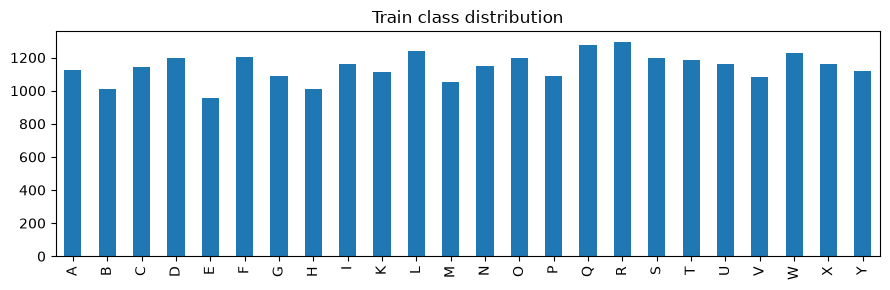

count      24.000000
mean     1143.958333
std        83.758701
min       957.000000
25%      1089.500000
50%      1156.000000
75%      1196.750000
max      1294.000000
Name: count, dtype: float64

In [5]:
counts = pd.Series(y_tr).value_counts().sort_index()
counts.index = [LETTERS[i] for i in counts.index]
ax = counts.plot.bar(figsize=(9, 3), title="Train class distribution")
ax.figure.tight_layout()
ax.figure.savefig(OUT_DIR / "class_distribution.png", dpi=120)
plt.show()
counts.describe()

## 5. Scale and reshape
Pixels to [0, 1] float32, shape `(N, 28, 28, 1)`.

In [6]:
X_tr = (X_tr / 255.0).astype(np.float32).reshape(-1, 28, 28, 1)
X_te = (X_te / 255.0).astype(np.float32).reshape(-1, 28, 28, 1)
X_tr.shape, X_tr.min(), X_tr.max()

((27455, 28, 28, 1), np.float32(0.0), np.float32(1.0))

## 6. Train / validation / test split
15% of the training data is held out as a stratified validation set. The provided test CSV stays as the test set.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_tr, y_tr, test_size=0.15, stratify=y_tr, random_state=SEED
)
print(f"train {len(X_train)}, val {len(X_val)}, test {len(X_te)}")

train 23336, val 4119, test 7172


## 7. Sample images

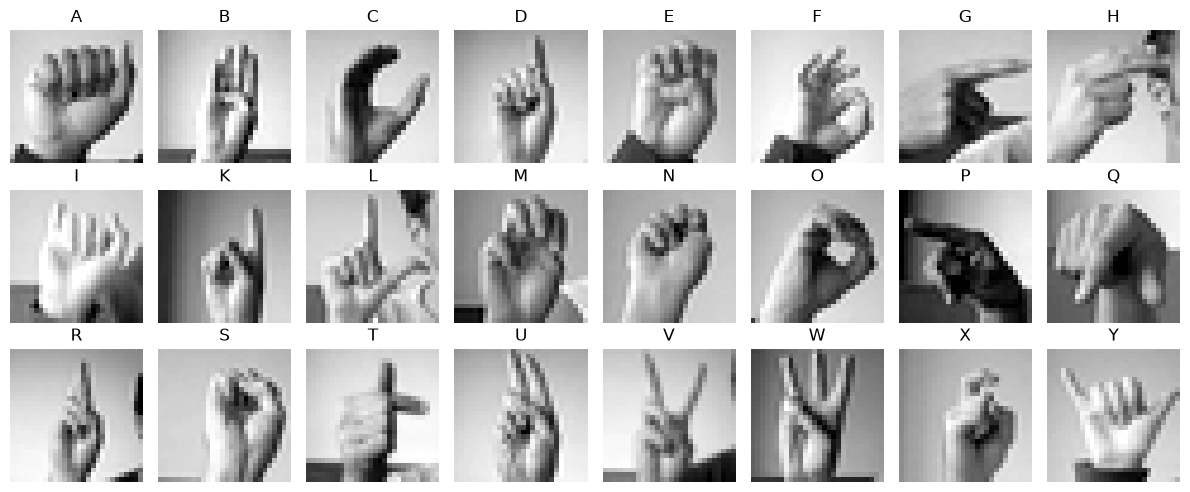

In [8]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[np.argmax(y_train == i)].squeeze(), cmap="gray")
    ax.set_title(LETTERS[i])
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "samples.png", dpi=120)
plt.show()

## 8. Save
Reload later with `d = np.load("processed/sign_mnist_processed.npz")`.

In [9]:
np.savez_compressed(
    OUT_DIR / "sign_mnist_processed.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_te, y_test=y_te,
    letters=np.array(LETTERS),
)
print("saved")

saved
